# Figure S10 — Short IDRs metapredict V3 misses: all ten examples in one figure

Panels A–J (`figure_S10A–J.ipynb`) in two columns with panel letters and one shared legend on top: A–E (short IDRs in loops between ordered residues) down the left column, F–H (next to unscored residues) and I–J (terminal tails) down the right. Each panel is drawn at the size of its single-panel notebook, with the same selection, tracks and AlphaFold2 renders (see the README).

**Output:** `figures/figure_S10.pdf`

In [1]:
import matplotlib.pyplot as plt

from caid3_panels import load_predictions, load_reference
from figtools import apply_style, label_panels, require_metapredict_3_1, save_panel
from short_idr_examples import (FIGSIZE, PANEL_LETTERS, add_legend, describe_selection, example_panel,
                                select_examples)

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

N_COLUMNS = 2
N_ROWS = 5  # examples per column: A-E on the left, F-J on the right
LEGEND_COLUMNS = 6  # the legend spans both columns, so it fits in two rows
# extra space between rows so each panel's x-axis label clears the header of the panel below (inches)
ROW_GAP_IN = 0.2

metapredict 3.1.0+7.g7dcf52c.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
reference = load_reference()
predictions = load_predictions(['Metapredict-v3', 'AlphaFold-pLDDT'])
examples = select_examples(reference, predictions['Metapredict-v3'])
describe_selection(examples)
assert len(examples) == N_COLUMNS * N_ROWS == len(PANEL_LETTERS)

/Users/alex/Dropbox/WASHU/Holehouse/public_data/github_repo/2026/metapredict_v3_2026/v3_updated/supplementary_figures/figure_S10/ground_truth_panels.py:266: RuntimeWarning: One or more sequences are no longer than the smoothing window used for domain decomposition (2*minimum_IDR_size residues). For those sequences the window is shrunk to match the sequence length.
  _smoothed, idrs, _fds = get_domains(


A: DP04063 (Delta-1-pyrroline-5-carboxylate dehydrogenase, mitochondrial), loop: V3 misses 4 of 4 short IDRs
B: DP04132 (Triggering receptor expressed on myeloid cells 2), loop: V3 misses 2 of 2 short IDRs
C: DP04127 (Telomere replication protein EST3), loop: V3 misses 4 of 4 short IDRs
D: DP04092 (Acetylcholine receptor subunit alpha), loop: V3 misses 2 of 2 short IDRs
E: DP04392 (E3 ubiquitin-protein ligase ipaH3), loop: V3 misses 2 of 4 short IDRs
F: DP03999 (Bis(5'-adenosyl)-triphosphatase), next to unscored: V3 misses 1 of 1 short IDRs
G: DP04185 (Asparagine--tRNA ligase, cytoplasmic), next to unscored: V3 misses 1 of 1 short IDRs
H: DP04193 (Islet amyloid polypeptide), next to unscored: V3 misses 1 of 1 short IDRs
I: DP04167 (NAD-dependent protein deacylase sirtuin-6), terminal tail: V3 misses 2 of 2 short IDRs
J: DP04128 (Large ribosomal subunit protein uL18B), terminal tail: V3 misses 1 of 1 short IDRs


Wrote figures/figure_S10.pdf


PosixPath('figures/figure_S10.pdf')

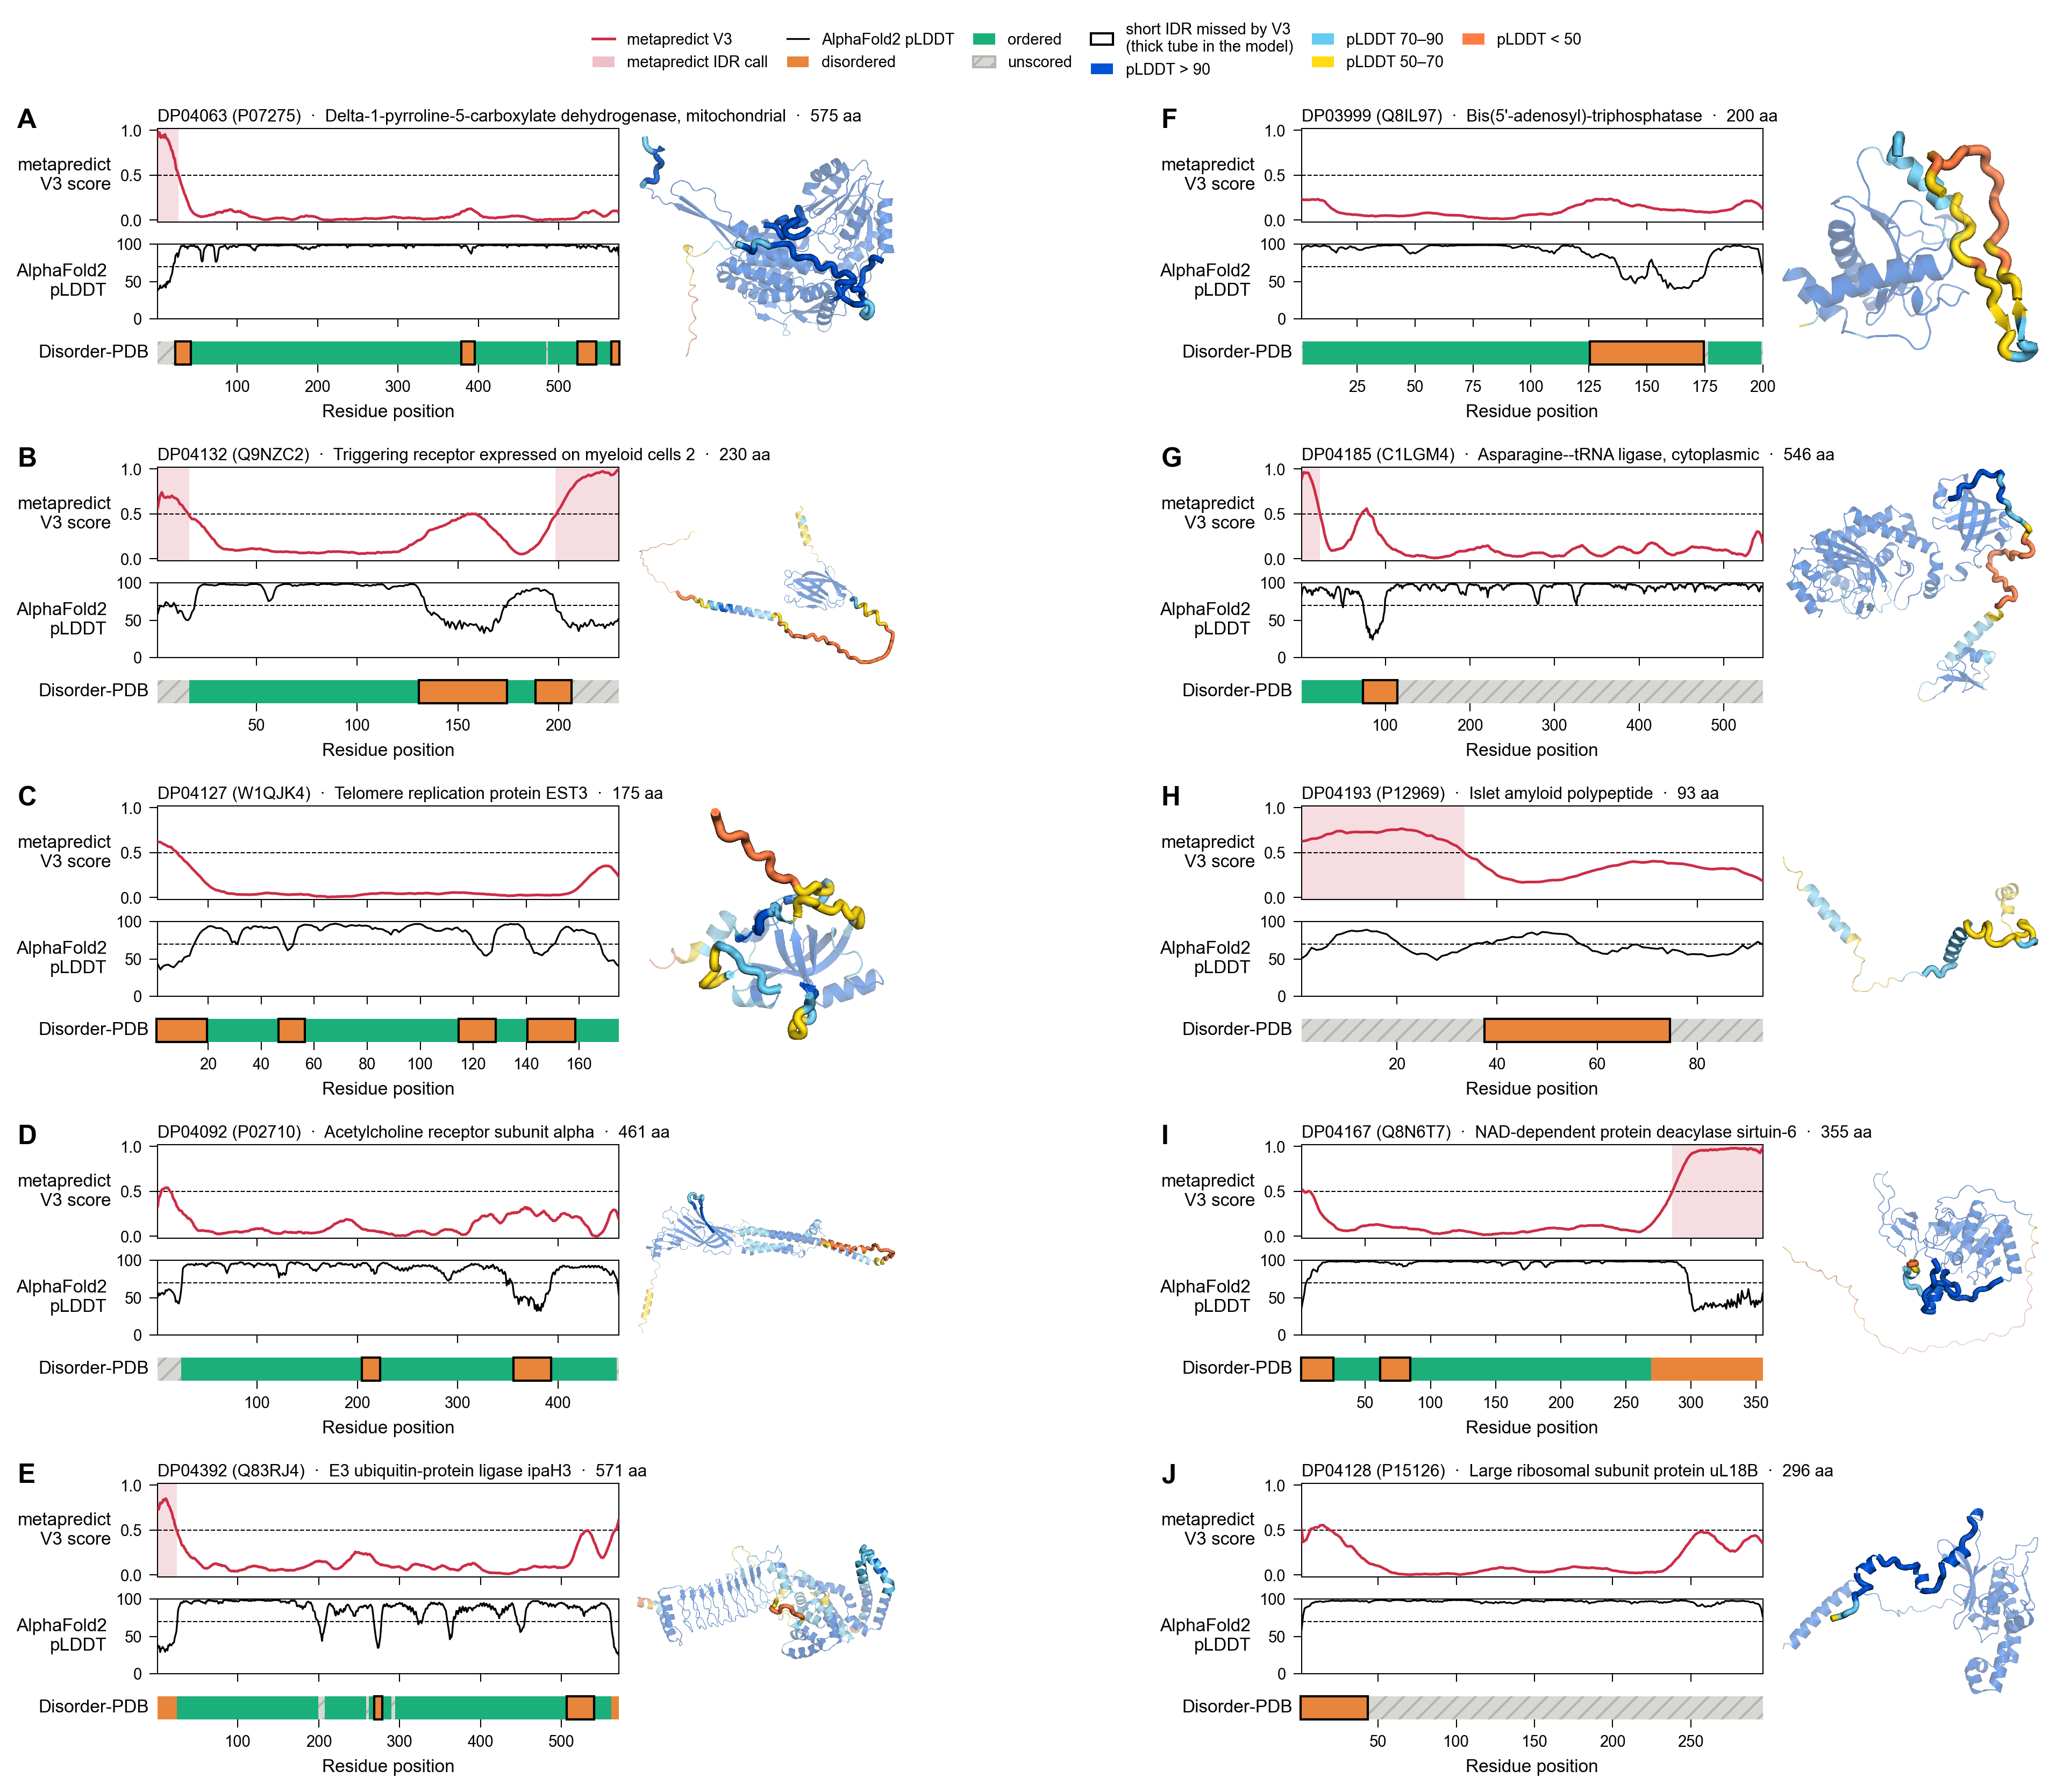

In [3]:
fig = plt.figure(figsize=(FIGSIZE[0] * N_COLUMNS, FIGSIZE[1] * N_ROWS + ROW_GAP_IN * (N_ROWS - 1)), dpi=150)
# hspace is a fraction of the row height, so each panel keeps its single-panel height
cells = fig.subfigures(N_ROWS, N_COLUMNS, hspace=ROW_GAP_IN / FIGSIZE[1])
panels = []
for index, example in enumerate(examples):
    # fill down the left column first, then the right
    column, row = divmod(index, N_ROWS)
    panels.append(example_panel(example, reference, predictions['Metapredict-v3'],
                                predictions['AlphaFold-pLDDT'], fig=cells[row, column]))
add_legend(fig, ncol=LEGEND_COLUMNS)

# letter each panel at its top track
label_panels(fig, [panel.axes[0] for panel in panels], PANEL_LETTERS)
save_panel(fig, 'figure_S10')